Mounted at /content/drive


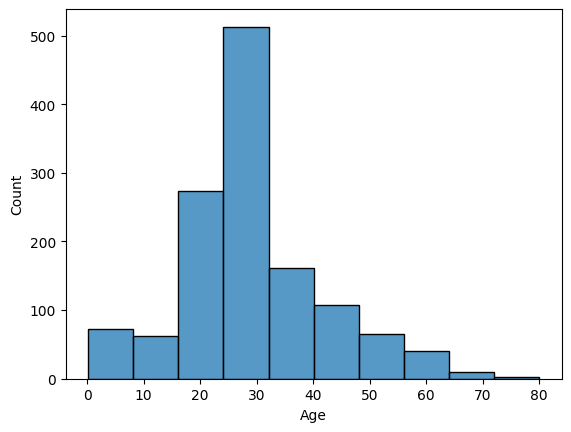

/tmp/ipykernel_2716/2585172599.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Sex', palette='viridis')


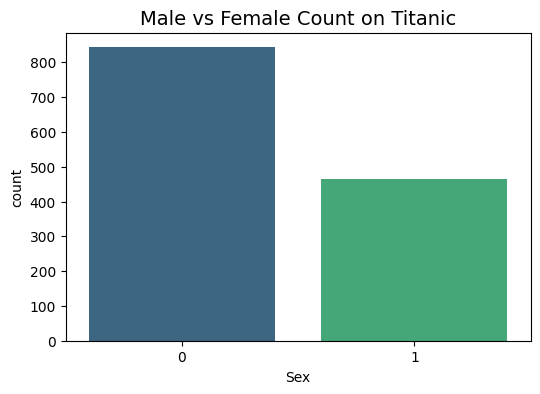

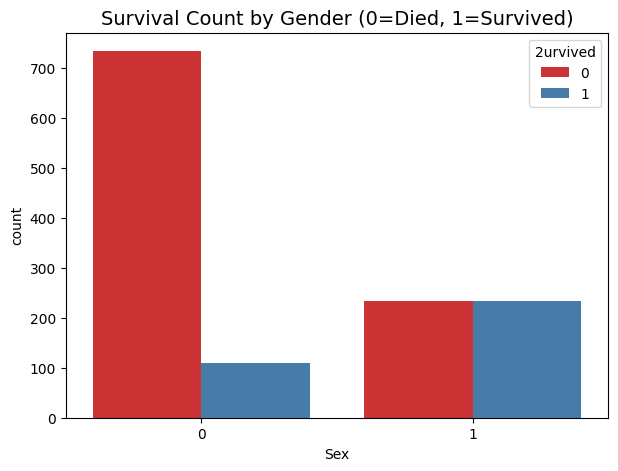

--- ਪ੍ਰਡਿਕਸ਼ਨ ਨਤੀਜੇ ---
ਮਰਨ ਵਾਲੇ (0): 200
ਬਚਣ ਵਾਲੇ (1): 62
Model ਪੱਕਾ ਹੈ 💯✅:  87.40458015267176


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
import matplotlib.pyplot as plt
import seaborn as sns

# 1. ਗੂਗਲ ਡਰਾਈਵ ਕਨੈਕਟ ਕਰੋ ਅਤੇ ਡਾਟਾ ਲੋਡ ਕਰੋ
from google.colab import drive
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/My Drive/titanic.csv')

# 2. ਮਿਸਿੰਗ ਵੈਲਯੂਜ਼ ਠੀਕ ਕਰੋ
df = df.fillna(0)
mean_age = df['Age'].mean()
df['Age'] = df['Age'].fillna(mean_age)

# 3. ਉਮਰ (Age) ਦਾ ਗ੍ਰਾਫ਼
sns.histplot(df['Age'], bins=10)
plt.show()

# 4. ਮੇਲ ਅਤੇ ਫੀਮੇਲ ਦੀ ਗਿਣਤੀ ਦਾ ਗ੍ਰਾਫ਼
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Sex', palette='viridis')
plt.title('Male vs Female Count on Titanic', fontsize=14)
plt.show()

# 5. ਲਿੰਗ ਦੇ ਹਿਸਾਬ ਨਾਲ ਬਚਣ/ਨਾ ਬਚਣ ਵਾਲਿਆਂ ਦਾ ਗ੍ਰਾਫ਼
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='Sex', hue='2urvived', palette='Set1')
plt.title('Survival Count by Gender (0=Died, 1=Survived)', fontsize=14)
plt.show()

# 6. ਮਾਡਲ ਟ੍ਰੇਨਿੰਗ ਅਤੇ ਸਕੋਰ
X = df.drop(columns=['2urvived'])
y = df['2urvived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42)
model.fit(X_train, y_train)

predicciions = model.predict(X_test)
counts = pd.Series(predicciions).value_counts()

print("--- ਪ੍ਰਡਿਕਸ਼ਨ ਨਤੀਜੇ ---")
print(f"ਮਰਨ ਵਾਲੇ (0): {counts.get(0, 0)}")
print(f"ਬਚਣ ਵਾਲੇ (1): {counts.get(1, 0)}")

scroes = model.score(X_test, y_test) * 100
if scroes >= 85:
    print("Model ਪੱਕਾ ਹੈ 💯✅: ", scroes)
else:
    print("ਸਿਰਫ਼ ਸੰਭਾਵਨਾ ਹੈ ਪੱਕਾ ਨਹੀਂ")